In [27]:
#!pip install pymc
#!pip install numpy
#!pip install arviz
#!pip install matplotlib

In [28]:
import pymc
import numpy as np
import arviz as az
import matplotlib.pyplot as plt

# SETUP

In [29]:
def var_transnoise(sigma, lam, dt):
  return sigma**2 / (2*lam) * (1 - np.exp(-2*lam*dt))

In [30]:
lambda_true = 2.0
sigma_fix = 0.5;

# initialize timestep and total time
dt = 0.1;
T = 10;
Nsteps = int(T/dt)
# generate data
x = np.zeros(Nsteps)
for i in range(1,Nsteps):
  a = np.exp(-lambda_true*dt)
  b = var_transnoise(sigma_fix, lambda_true, dt)
  x[i] = x[i-1] * a + b * np.random.randn()

# Task 1

/usr/local/lib/python3.12/dist-packages/pymc/distributions/timeseries.py:595: UserWarning: Initial distribution not specified, defaulting to `Normal.dist(0, 100, shape=...)`. You can specify an init_dist manually to suppress this warning.
  warnings.warn(


Output()

       mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
lam  31.651  4.759  23.018   40.523      0.118     0.07    1577.0    2887.0   

     r_hat  
lam    1.0  


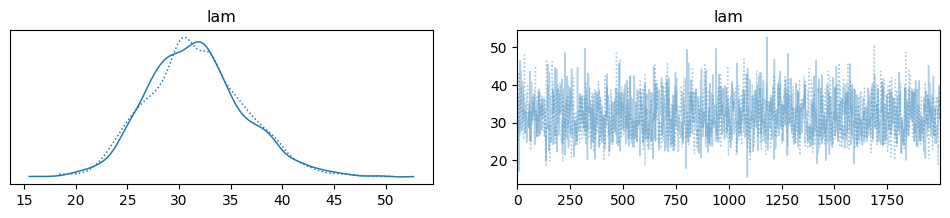

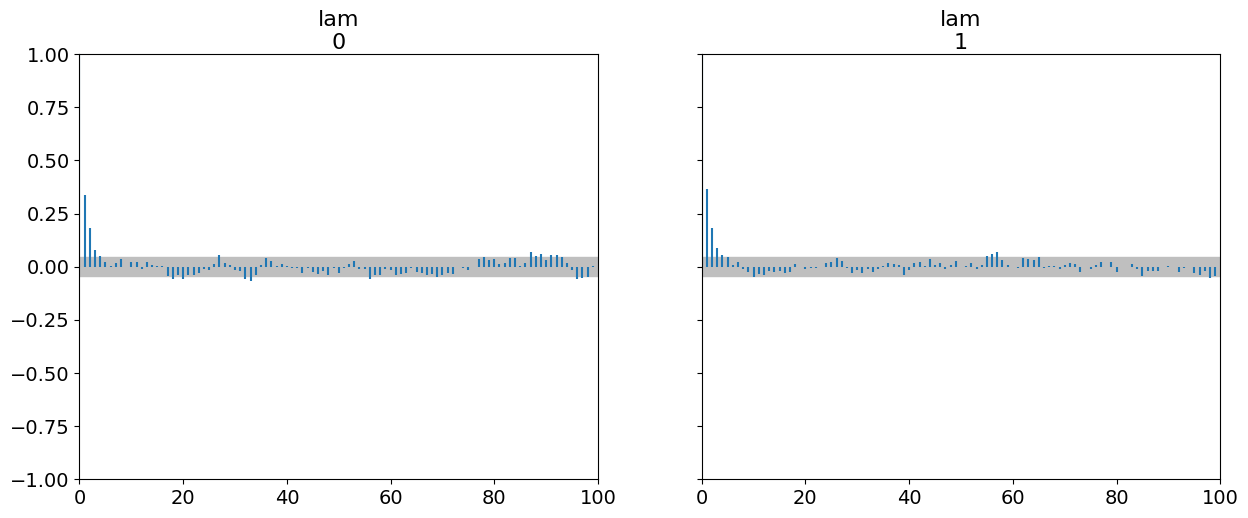

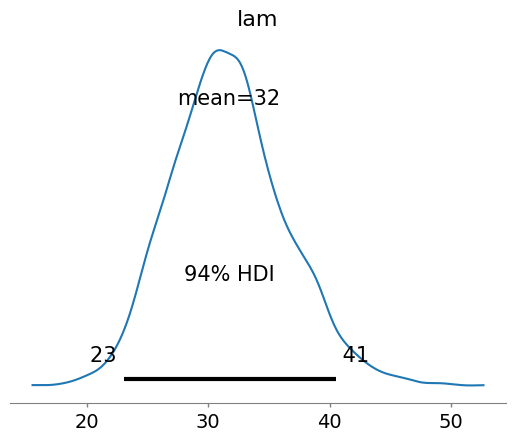

In [26]:
# the model
with pymc.Model() as model:
  # 1.1 The prior (proposal > 0)
  lam = pymc.Exponential('lam', lam=1)
  # 1.2 Likelihood (rho, tau)
  rho = pymc.math.exp(-lam*dt)
  # variance of the noise term
  step_variance = var_transnoise(sigma_fix, lam, dt)
  step_sigma = pymc.math.sqrt(step_variance)
  # likelihood: AR(1) distribution
  observ = pymc.AR('obs', rho=rho, sigma=step_sigma, observed=x)
  trace1 = pymc.sample(2000, tune=1000, chains=2, progressbar=False)
# plots
  print(az.summary(trace1)) # ess, oess, mcse_mean
  az.plot_trace(trace1) # chains and densities
  az.plot_autocorr(trace1) # ACF
  az.plot_posterior(trace1) # posterior estimates

# Task 2

/usr/local/lib/python3.12/dist-packages/pymc/distributions/timeseries.py:595: UserWarning: Initial distribution not specified, defaulting to `Normal.dist(0, 100, shape=...)`. You can specify an init_dist manually to suppress this warning.
  warnings.warn(


Output()

/usr/local/lib/python3.12/dist-packages/pymc/distributions/timeseries.py:595: UserWarning: Initial distribution not specified, defaulting to `Normal.dist(0, 100, shape=...)`. You can specify an init_dist manually to suppress this warning.
  warnings.warn(


Output()

/usr/local/lib/python3.12/dist-packages/pymc/distributions/timeseries.py:595: UserWarning: Initial distribution not specified, defaulting to `Normal.dist(0, 100, shape=...)`. You can specify an init_dist manually to suppress this warning.
  warnings.warn(


Output()

##### Gaussian ###### 

        mean    sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
lam_2  4.278  0.94   2.575    6.077      0.035     0.02     719.0    1221.0   

       r_hat  
lam_2    1.0  


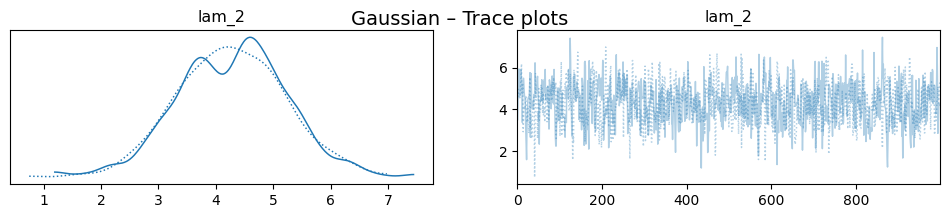

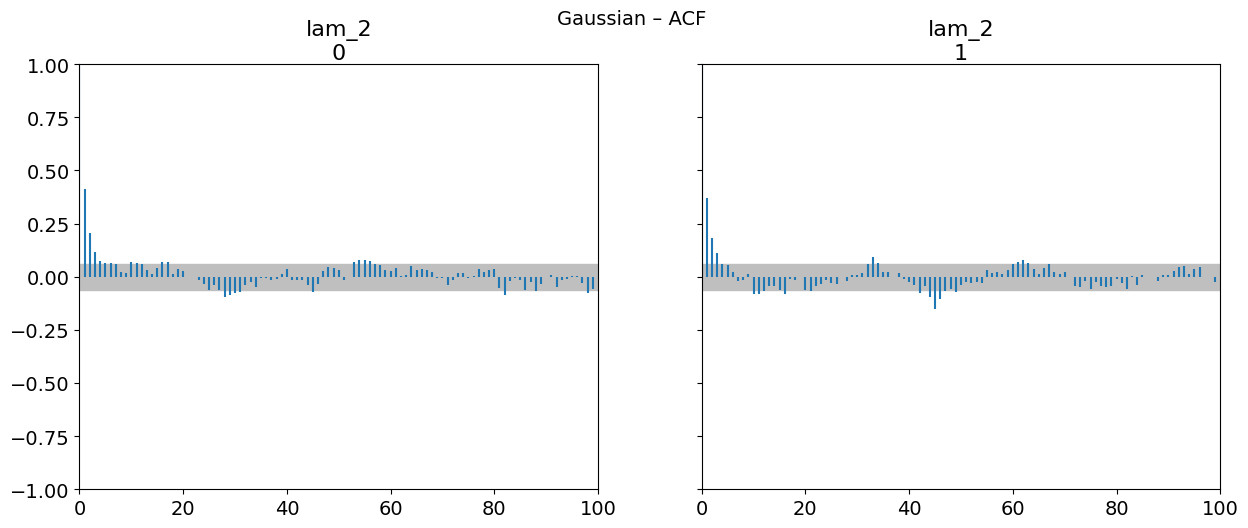

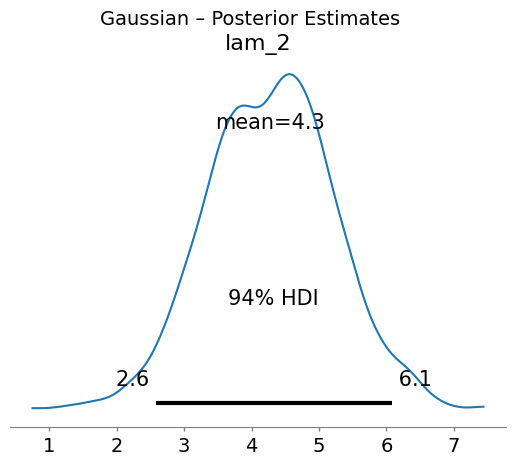



##### Lognormal ###### 

          mean      sd   hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  \
lam_2  395.602  59.426  292.131  509.718      1.863    1.374    1004.0   

       ess_tail  r_hat  
lam_2    1141.0    1.0  


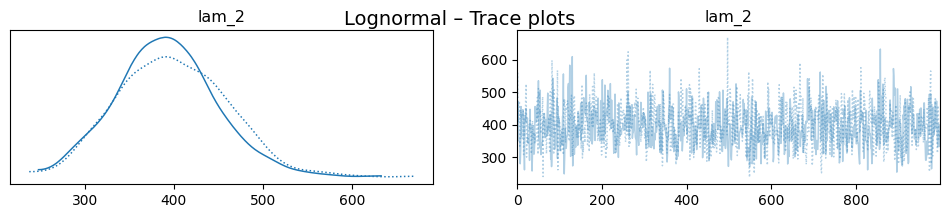

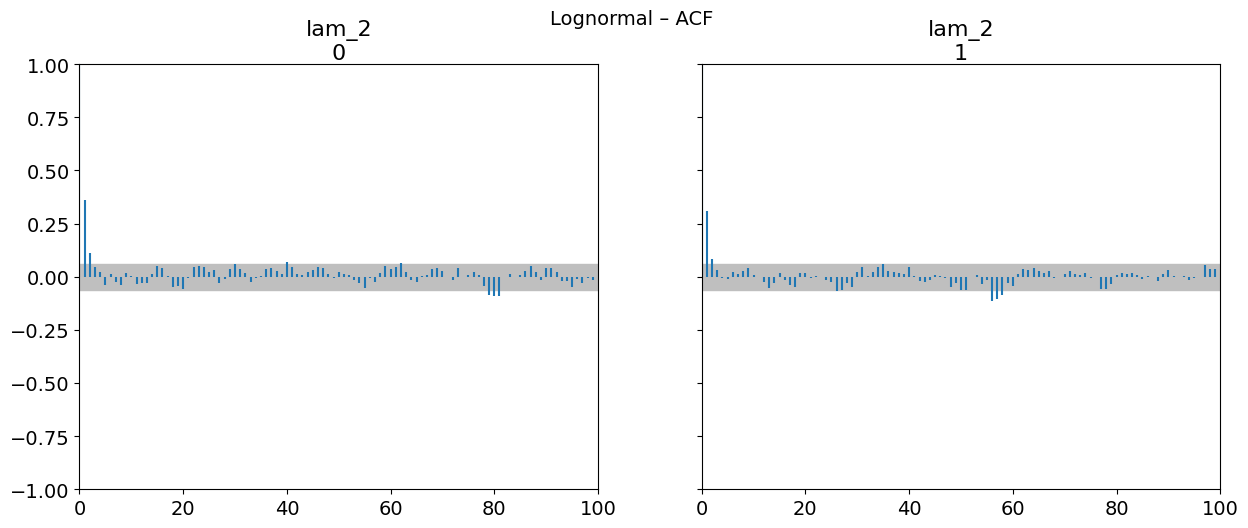

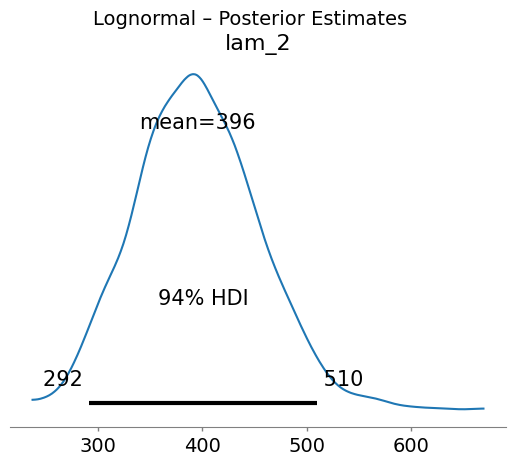



##### Uniform ###### 

        mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
lam_2  9.699  0.287   9.153     10.0       0.01    0.012     568.0     616.0   

       r_hat  
lam_2    1.0  


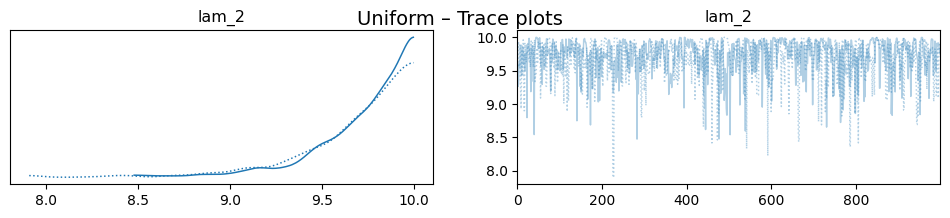

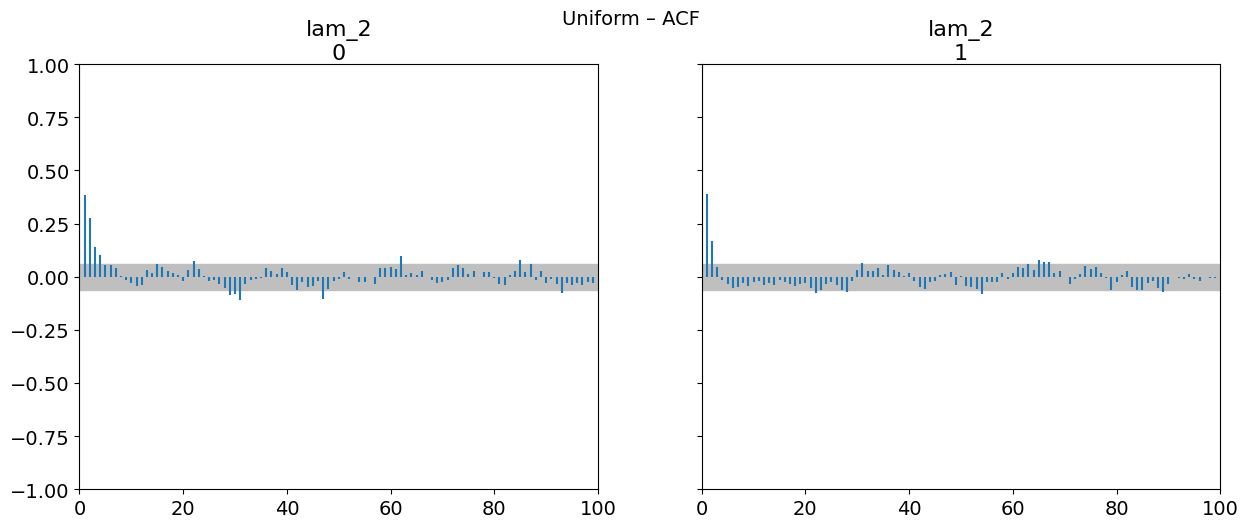

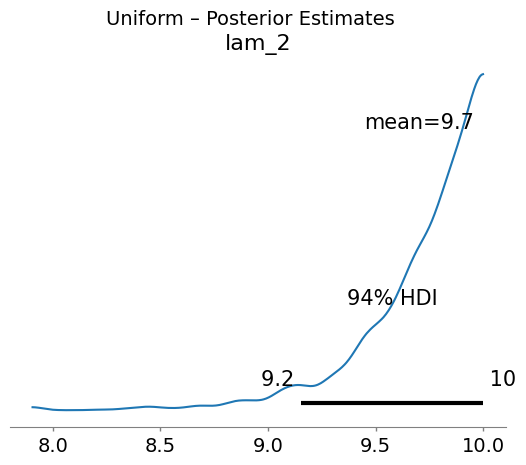

In [31]:
results = {}
for prior_name in ["Gaussian", "Lognormal", "Uniform"]:
  with pymc.Model() as model:
    if prior_name == "Gaussian":
      lam_2 = pymc.Normal('lam_2', mu=0, sigma=1)
    elif prior_name == "Lognormal":
      lam_2 = pymc.LogNormal('lam_2', mu=0, sigma=1)
    elif prior_name == "Uniform":
      lam_2 = pymc.Uniform('lam_2', lower=0, upper=10)
    # 2.2 Likelihood (rho, tau)
    rho = pymc.math.exp(-lam_2*dt)
    # variance of the noise term
    step_sigma = pymc.math.sqrt((0.8**2 / (2*lam_2)) * (1-pymc.math.exp(-2*lam_2*dt)))
    observ = pymc.AR('obs', rho=rho, sigma=step_sigma, observed=x)
    results[prior_name] = pymc.sample(1000, tune=1000, progressbar=False)

# plotting
for name in ["Gaussian", "Lognormal", "Uniform"]:
  trace2 = results[name]
  print(f"##### {name} ###### \n")
  print(az.summary(trace2))

  az.plot_trace(trace2) # chains and densities
  plt.suptitle(f"{name} – Trace plots", fontsize=14)
  plt.show()

  az.plot_autocorr(trace2) # ACF
  plt.suptitle(f"{name} – ACF", fontsize=14)
  plt.show()

  az.plot_posterior(trace2) # posterior estimates
  plt.suptitle(f"{name} – Posterior Estimates", fontsize=14)
  plt.show()
  print("\n")
  # The interior posterior using Gauss seems somewhat reasonable.
  # There could be a need for higher lambdas
  # for uniform the lambdas dont settle, the lambdas are not large enough

# Task 3

/usr/local/lib/python3.12/dist-packages/pymc/distributions/timeseries.py:595: UserWarning: Initial distribution not specified, defaulting to `Normal.dist(0, 100, shape=...)`. You can specify an init_dist manually to suppress this warning.
  warnings.warn(


Output()

##### Trace3 ###### 

      mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
lam  3.140  0.992   1.296    4.966      0.030    0.024    1117.0    1093.0   
sig  0.522  0.028   0.470    0.574      0.001    0.001    1198.0    1052.0   

     r_hat  
lam    1.0  
sig    1.0  


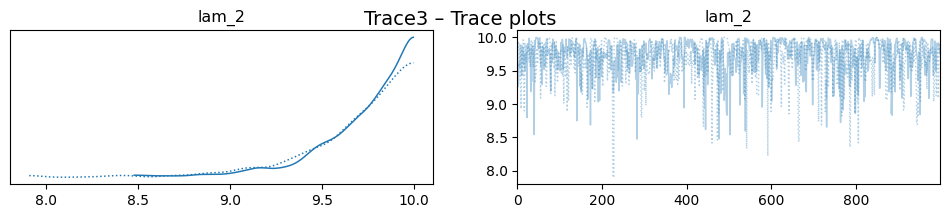

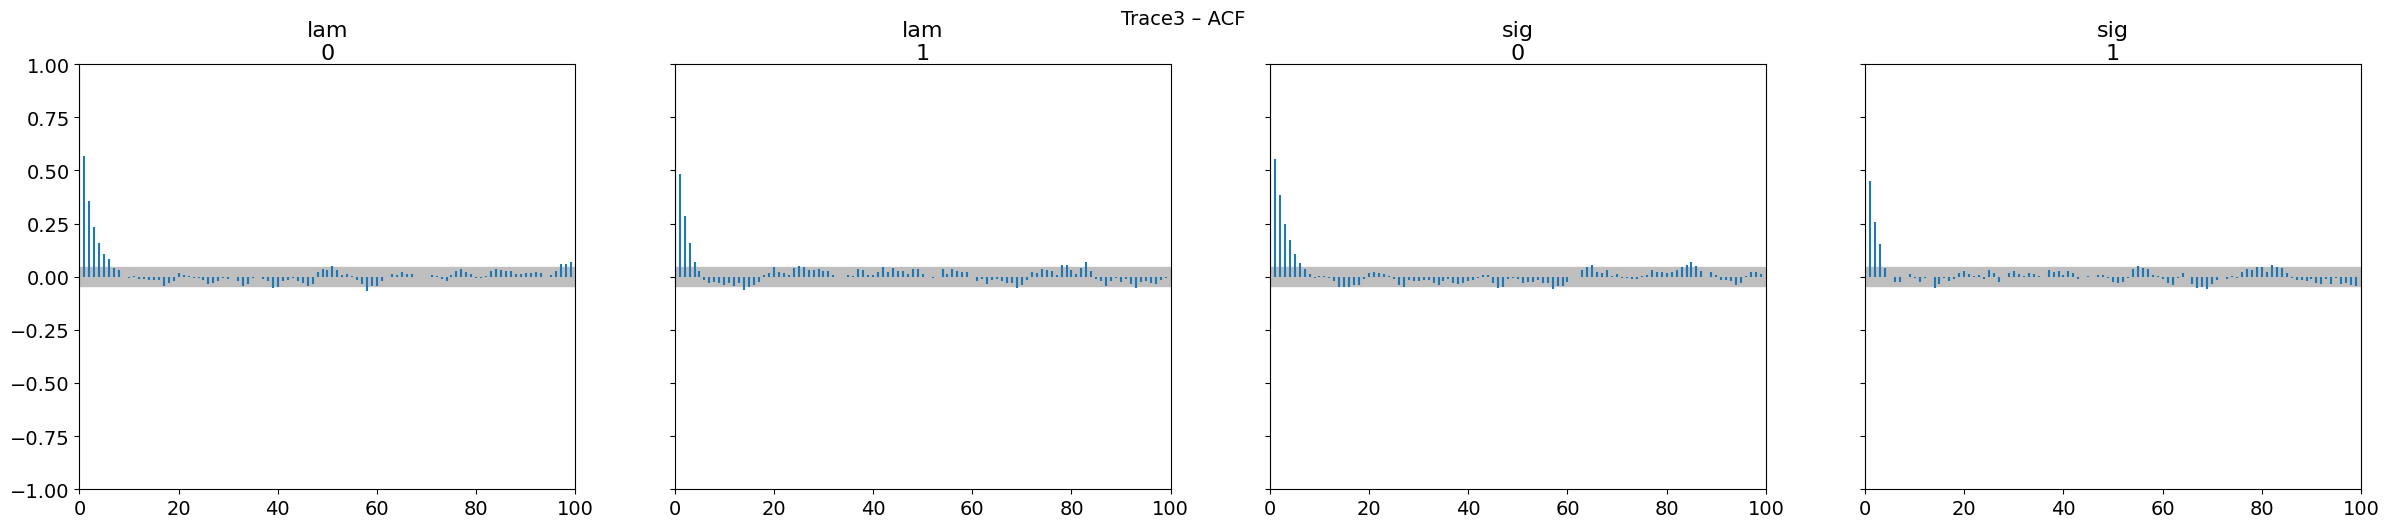

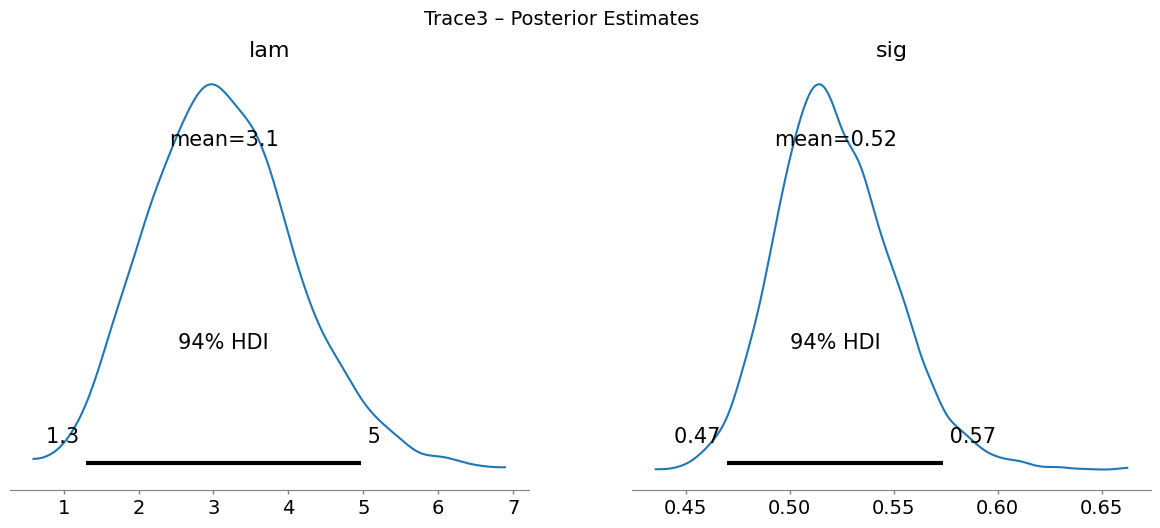

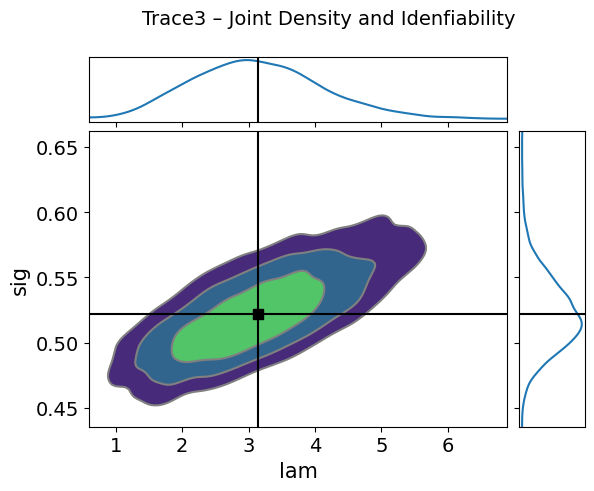

In [35]:
with pymc.Model() as model3:
  lam_3 = pymc.Exponential("lam",lam=1.0)
  sigma_3 = pymc.HalfNormal("sig", sigma=2)
  rho = pymc.math.exp(-lam_3*dt)
  step_sigma_3 = var_transnoise(sigma_3,lam_3,dt)

  pymc.AR("obs", rho=rho, sigma=step_sigma_3, observed=x)
  trace3 = pymc.sample(2000, tune=1000, chains=2, progress_bar=False)

# plots and results
print(f"##### Trace3 ###### \n")
print(az.summary(trace3))

az.plot_trace(trace2) # chains and densities
plt.suptitle(f"Trace3 – Trace plots", fontsize=14)
plt.show()

az.plot_autocorr(trace3) # ACF
plt.suptitle(f"Trace3 – ACF", fontsize=14)
plt.show()

az.plot_posterior(trace3) # posterior estimates
plt.suptitle(f"Trace3 – Posterior Estimates", fontsize=14)
plt.show()
print("\n")
# also join density and marginal densities
az.plot_pair(trace3, kind='kde', marginals=True, point_estimate='mean')
plt.suptitle(f"Trace3 – Joint Density and Idenfiability", fontsize=14)
plt.show()
# so when lambda is fixed, the transition of OU has nonlinear relation to sigma2
# elliptic shape indicates correlation between the paramters
# the parameters are jointly identifiable i think
